In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("train.csv")
a = df.columns
print(a)
print(df['merchant_category'].value_counts())

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')
merchant_category
Online Retail      155097
Groceries          142578
Restaurants        101360
Fuel                59880
Electronics         48693
Streaming           47196
Utilities           42027
Healthcare          35889
Travel              28715
Gaming              23784
Gift Cards           9456
Crypto Exchange      5285
Name: count, dtype: int64


In [ ]:
cat = 0
num = 0

with open("describe.txt", "w", encoding="utf-8") as f:
  for i in a:
    f.write("--------" + i + "--------" + "\n")

    if df[i].nunique() < 20:
      f.write(df[i].value_counts().to_string() + "\n")
      cat += 1
    else :
      f.write(df[i].describe().to_string() + "\n")
      num += 1
    f.write("\n")
print(cat)
print(num)

16
10


Top các cột tương quan với is_fraud:
is_fraud                        1.000000
cvv_retry_count                 0.212290
ip_country_mismatch             0.148284
merchant_risk_score             0.125391
is_foreign_transaction          0.112832
velocity_score                  0.101650
is_new_merchant                 0.101412
billing_shipping_mismatch       0.101115
used_vpn                        0.071235
is_ai_generated_scam_attempt    0.060719
txn_count_last_24h              0.058035
customer_age                    0.056051
prior_disputes                  0.023644
amount_usd                      0.019443
day_of_week                     0.003651
distance_from_home_km           0.001826
account_balance_usd             0.001077
card_age_months                 0.000681
time_of_day_hour               -0.000050
id                             -0.000644
hours_since_last_txn           -0.020490
Name: is_fraud, dtype: float64


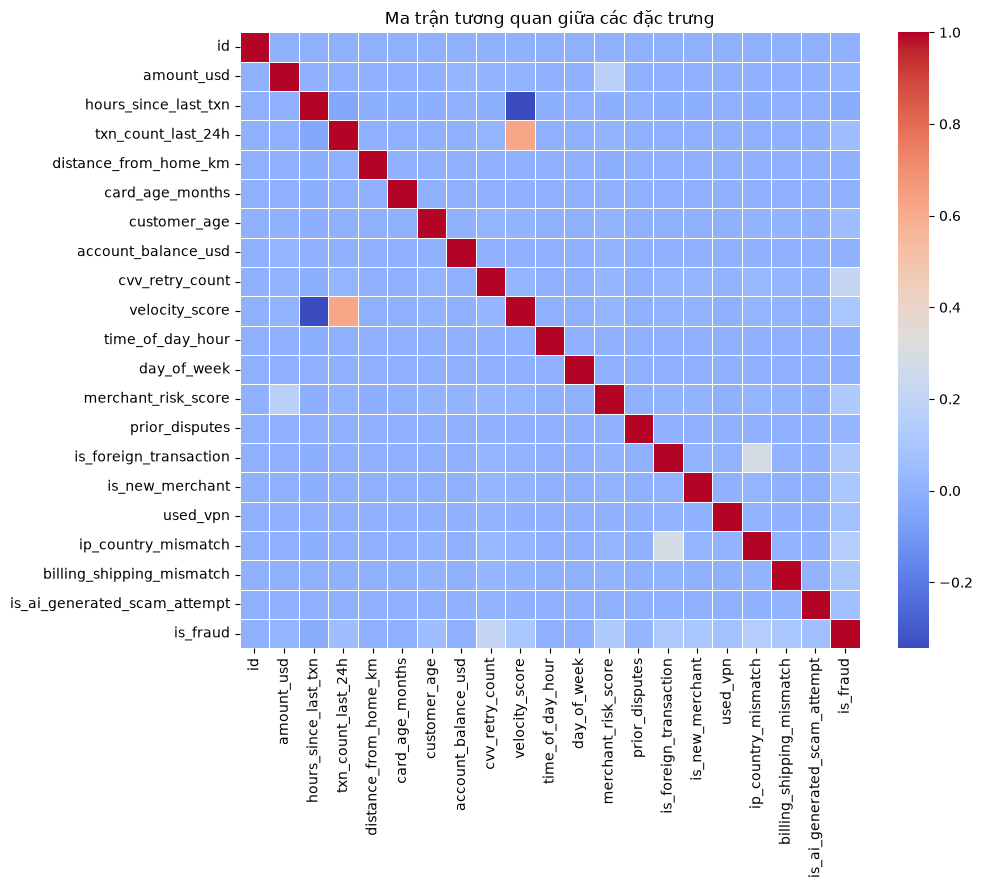

In [6]:
corr_matrix = df.corr(numeric_only=True)

# 2. Xem độ tương quan của các cột khác đối với biến mục tiêu (is_fraud)
fraud_corr = corr_matrix['is_fraud'].sort_values(ascending=False)
print("Top các cột tương quan với is_fraud:")
print(fraud_corr)

# 3. Vẽ biểu đồ nhiệt (Heatmap) để trực quan hóa toàn bộ ma trận
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Ma trận tương quan giữa các đặc trưng")
plt.show()